# Part 3: Transaction Costs and Turnover

### Ramith Vaid | NTU Singapore

The README's Known Limitations say it plainly: *"Long-only, no transaction costs. Portfolios are rebalanced fresh at each window with no penalty for turnover between periods. A real implementation would need to weigh the benefit of a more responsive covariance estimate against the trading costs of acting on it more frequently."* This notebook adds that.

**What is new.**
1. **A cost model in the rolling validation.** Every rebalance pays `cost x sum |w_new - w_drifted|`, a proportional cost on each unit of portfolio value traded (buys and sells both counted). `w_drifted` is last window's portfolio after it has drifted with the assets' own returns, so turnover is measured against what is actually held on rebalance day, not against last window's target weights.
2. **A turnover penalty in the optimization objective.** `max_sharpe_with_turnover_penalty` maximizes the Sharpe ratio of expected excess return *net of the annualized cost of trading* from the drifted holdings, with the same 35% cap and long-only constraint as before.
3. **A net-of-cost comparison** of realized performance, not just of volatility prediction error.

**Applied to all three covariance methods, not just one.** The cost treatment is run on top of the sample covariance, Part 1's GARCH + static correlation, and Part 2's GARCH + DCC correlation, each both *cost-blind* (the Part 1/2 optimizer, which ignores trading cost when choosing weights but still pays it) and *cost-aware* (with the turnover penalty). That way the cost effect and the correlation-method effect are not tangled: the covariance method is the only thing that changes across the three rows, and the cost treatment is the only thing that changes across the two columns. An equal-weight (1/N) portfolio rebalanced every window is included as a reference.

**What this measures, and how it differs from Parts 1 and 2.** Parts 1 and 2 scored each covariance estimate by how well it *predicted portfolio volatility*. A net-of-cost comparison needs realized *returns*, so the headline here is net annualized return, volatility and Sharpe ratio of the realized out-of-sample portfolio, concatenated over all 15 test windows. That is a different and noisier question than volatility prediction (Max Sharpe weights also depend on the 5-year mean returns, which are estimated poorly), so a covariance method that predicts volatility better need not deliver a better Sharpe ratio, and this notebook checks whether it does.

**Conventions.** Costs: 10 bps (0.10%) per unit traded as the headline, with 0, 5, 25, 50 and 100 bps as a sensitivity range. 10 bps is a round number for large-cap US stocks, chosen before looking at results, not a calibrated estimate. Windows are the same 15 non-overlapping 6-month windows (5-year train) as Parts 1 and 2. Window 1 starts fully invested with no entry cost for every strategy, so costs come from the 14 rebalances. Inside a window the portfolio is buy-and-hold. Sharpe uses the same 2% risk-free rate as the optimizer. The end date is pinned to 2026-10-13 as in Parts 1 and 2.

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from portfolio_utils import (
    max_sharpe_portfolio, max_sharpe_with_turnover_penalty, build_window_inputs,
    simulate_strategy, performance_summary
)

print('Libraries loaded.')

Libraries loaded.


## 1. Data Collection (same universe and range as Parts 1 and 2, end date pinned)

In [2]:
TICKERS = {
    'JPM':  'Financials',
    'AAPL': 'Technology',
    'XOM':  'Energy',
    'JNJ':  'Healthcare',
    'PG':   'Consumer Staples',
    'CAT':  'Industrials',
    'NEE':  'Utilities',
    'AMZN': 'Consumer Discretionary',
}
START = '2014-01-01'
END = '2026-10-14'  # exclusive: last row is 2026-10-13, matching Parts 1 and 2
tickers = list(TICKERS.keys())
n_assets = len(tickers)

prices = {}
for ticker, sector in TICKERS.items():
    df = yf.download(ticker, start=START, end=END, progress=False)
    prices[ticker] = df['Close'].squeeze()

price_df = pd.DataFrame(prices).dropna()
log_returns = np.log(price_df / price_df.shift(1)).dropna()
print(f'{price_df.shape[0]} trading days, {price_df.shape[1]} assets '
      f'({price_df.index[0].date()} to {price_df.index[-1].date()})')

3214 trading days, 8 assets (2014-01-02 to 2026-10-13)


## 2. Sanity checks on the cost-aware optimizer

Before using it: with zero cost it must equal the plain Max Sharpe weights, and as the cost grows the optimizer must trade less, ending at "do not trade" when the cost is prohibitive. Checked on the full-sample estimates, starting from equal weights.

In [3]:
from portfolio_utils import build_garch_covariance
ANNUALIZE = 252
mean_full = log_returns.mean() * ANNUALIZE
cov_full, _ = build_garch_covariance(log_returns, tickers)
w_start = np.ones(n_assets) / n_assets
w_plain = max_sharpe_portfolio(mean_full, cov_full, n_assets)
print(f'{"cost":>8} {"turnover from 1/N":>20} {"max weight":>12}')
for c in (0.0, 0.0005, 0.001, 0.0025, 0.005, 0.01, 0.1):
    w = max_sharpe_with_turnover_penalty(mean_full, cov_full, n_assets, w_start, c)
    print(f'{c*1e4:>6.0f}bp {np.abs(w - w_start).sum():>20.3f} {w.max():>12.3f}')
print(f'\nZero-cost weights equal plain Max Sharpe: {np.allclose(max_sharpe_with_turnover_penalty(mean_full, cov_full, n_assets, w_start, 0.0), w_plain)}')
print(f'Plain Max Sharpe turnover from 1/N: {np.abs(w_plain - w_start).sum():.3f}')

    cost    turnover from 1/N   max weight
     0bp                1.121        0.350
     5bp                1.107        0.350
    10bp                1.092        0.350
    25bp                1.050        0.350
    50bp                0.909        0.350
   100bp                0.687        0.350
  1000bp                0.000        0.125

Zero-cost weights equal plain Max Sharpe: True
Plain Max Sharpe turnover from 1/N: 1.121


## 3. Build the per-window estimates

For each of the 15 windows, from the training data only: mean returns and the three covariance estimates. These are built once and reused by every strategy and cost level below, so any difference between strategies comes from how they use the same estimates, not from re-fitting. Each window fits 8 GARCH models plus a DCC model, so this takes a few minutes.

In [4]:
window_inputs = build_window_inputs(log_returns, tickers, annualize=ANNUALIZE, train_years=5, test_months=6)
print(f'\n{len(window_inputs)} windows; first test start {window_inputs[0]["test_start"]}, last {window_inputs[-1]["test_start"]}')

  Window 1/15 inputs built (test starting 2019-01-07)


  Window 2/15 inputs built (test starting 2019-07-09)


  Window 3/15 inputs built (test starting 2020-01-07)


  Window 4/15 inputs built (test starting 2020-07-08)


  Window 5/15 inputs built (test starting 2021-01-06)


...

  Window 11/15 inputs built (test starting 2024-01-09)


  Window 12/15 inputs built (test starting 2024-07-11)


  Window 13/15 inputs built (test starting 2025-01-10)


  Window 14/15 inputs built (test starting 2025-07-15)


  Window 15/15 inputs built (test starting 2026-01-13)

15 windows; first test start 2019-01-07, last 2026-01-13


## 4. Headline comparison at 10 bps

Each row is a strategy rolled through the 15 windows in order. *Cost-blind* strategies choose weights with the Part 1/2 optimizer and pay the cost anyway; *cost-aware* ones include the turnover penalty. Returns, volatility and Sharpe are computed from the concatenated daily returns of all 15 test windows (1,890 days), gross and net of cost.

In [5]:
COST = 0.0010
STRATS = [('sample', 'Sample covariance'), ('garch_static', 'GARCH + static corr'), ('garch_dcc', 'GARCH + DCC corr')]

def run_all(cost):
    out = {}
    for key, label in STRATS:
        for aware in (False, True):
            out[(key, aware)] = simulate_strategy(window_inputs, n_assets, key, cost, aware)
    out[('equal_weight', False)] = simulate_strategy(window_inputs, n_assets, 'equal_weight', cost, False)
    return out

def summarize(runs, cost):
    rows = []
    for (key, aware), (wdf, net, gross) in runs.items():
        label = dict(STRATS).get(key, 'Equal weight (1/N)')
        g, n_ = performance_summary(gross), performance_summary(net)
        rows.append({'covariance': label, 'optimizer': 'cost-aware' if aware else ('n/a' if key == 'equal_weight' else 'cost-blind'),
                     'cost_bps': cost * 1e4,
                     'gross_return_%': g['ann_return'] * 100, 'net_return_%': n_['ann_return'] * 100,
                     'vol_%': n_['ann_vol'] * 100, 'gross_sharpe': g['sharpe'], 'net_sharpe': n_['sharpe'],
                     'avg_turnover': wdf['turnover'].iloc[1:].mean(), 'cost_drag_%_per_yr': (g['ann_return'] - n_['ann_return']) * 100})
    return pd.DataFrame(rows)

runs10 = run_all(COST)
head = summarize(runs10, COST)
pd.set_option('display.float_format', lambda v: f'{v:,.3f}')
pd.set_option('display.width', 220)
print(head.drop(columns='cost_bps').to_string(index=False))

         covariance  optimizer  gross_return_%  net_return_%  vol_%  gross_sharpe  net_sharpe  avg_turnover  cost_drag_%_per_yr
  Sample covariance cost-blind          18.747        18.662 21.061         0.795       0.791         0.385               0.085
  Sample covariance cost-aware          18.622        18.539 21.063         0.789       0.785         0.372               0.082
GARCH + static corr cost-blind          19.246        19.117 20.084         0.859       0.852         0.581               0.129
GARCH + static corr cost-aware          19.437        19.317 20.131         0.866       0.860         0.538               0.120
   GARCH + DCC corr cost-blind          18.750        18.629 19.463         0.861       0.854         0.549               0.122
   GARCH + DCC corr cost-aware          18.837        18.725 19.470         0.865       0.859         0.506               0.112
 Equal weight (1/N)        n/a          21.698        21.672 17.847         1.104       1.102         0.

## 5. Sensitivity to the cost level

The 10 bps headline is a round number, not a measured one, so the whole comparison is repeated at 0, 5, 25, 50 and 100 bps. At each level the cost-aware optimizer is told the same cost that is charged.

In [6]:
LEVELS_BPS = [0, 5, 10, 25, 50, 100]
sens_parts = []
for bps in LEVELS_BPS:
    runs = runs10 if bps == 10 else run_all(bps / 1e4)
    sens_parts.append(summarize(runs, bps / 1e4))
sens = pd.concat(sens_parts, ignore_index=True)
sens['strategy'] = sens['covariance'] + np.where(sens['optimizer'] == 'cost-aware', ' (cost-aware)',
                                                 np.where(sens['optimizer'] == 'cost-blind', ' (cost-blind)', ''))
print('Net Sharpe ratio by cost level:')
print(sens.pivot(index='strategy', columns='cost_bps', values='net_sharpe').to_string())
print()
print('Net annualized return (%) by cost level:')
print(sens.pivot(index='strategy', columns='cost_bps', values='net_return_%').to_string())
print()
print('Average turnover per rebalance (sum of |trades|, 1.0 = trading the whole portfolio once), by cost level:')
print(sens.pivot(index='strategy', columns='cost_bps', values='avg_turnover').to_string())

Net Sharpe ratio by cost level:
cost_bps                          0.000    5.000    10.000   25.000   50.000   100.000
strategy                                                                              
Equal weight (1/N)                  1.104    1.103    1.102    1.100    1.097    1.089
GARCH + DCC corr (cost-aware)       0.861    0.860    0.859    0.856    0.865    0.874
GARCH + DCC corr (cost-blind)       0.861    0.858    0.854    0.845    0.829    0.798
GARCH + static corr (cost-aware)    0.859    0.860    0.860    0.857    0.861    0.857
GARCH + static corr (cost-blind)    0.859    0.856    0.852    0.843    0.826    0.794
Sample covariance (cost-aware)      0.795    0.790    0.785    0.772    0.764    0.765
Sample covariance (cost-blind)      0.795    0.793    0.791    0.785    0.775    0.754

Net annualized return (%) by cost level:
cost_bps                          0.000    5.000    10.000   25.000   50.000   100.000
strategy                                                

## 6. Turnover per window

Turnover is `sum |w_new - w_drifted|` at each of the 14 rebalances. Cost-blind Max Sharpe re-solves from scratch every window, and the weights respond to noisy 5-year mean returns, so this shows how much trading that implies.

In [7]:
turn = pd.DataFrame({
    label: runs10[(key, False)][0].set_index('test_start')['turnover'] for key, label in STRATS
})
turn['Equal weight (1/N)'] = runs10[('equal_weight', False)][0].set_index('test_start')['turnover']
print(turn.iloc[1:].to_string())
print()
print('Mean turnover per rebalance (14 rebalances):')
print(turn.iloc[1:].mean().to_string())
print()
for key, label in STRATS:
    wdf = runs10[(key, False)][0]
    print(f'{label}: windows with a holding at the 35% cap: {int((wdf["max_weight"] >= 0.3499).sum())} of {len(wdf)}; '
          f'median number of holdings {int(wdf["n_holdings"].median())}')

            Sample covariance  GARCH + static corr  GARCH + DCC corr  Equal weight (1/N)
test_start                                                                              
2019-07-09              0.356                0.373             0.408               0.069
2020-01-07              0.231                0.151             0.200               0.112
2020-07-08              0.507                0.605             0.673               0.208
2021-01-06              0.252                0.685             0.743               0.112
2021-07-08              0.274                0.934             0.852               0.086
2022-01-05              0.366                0.621             0.550               0.083
2022-07-08              0.356                0.782             0.792               0.160
2023-01-06              0.180                0.565             0.518               0.153
2023-07-11              0.495                0.398             0.450               0.181
2024-01-09           

## 7. Does the covariance ranking survive costs?

Parts 1 and 2 found GARCH + static and GARCH + DCC predicted portfolio volatility better than the sample covariance. Here the question is the realized, net-of-cost outcome. For each pair, the mean difference in net per-window return and a paired t-statistic over the 15 windows (indicative only: 15 windows, and window returns are noisy and not independent draws).

In [8]:
def paired(a_key, a_aware, b_key, b_aware):
    a = runs10[(a_key, a_aware)][0]['net_window_return'].values
    b = runs10[(b_key, b_aware)][0]['net_window_return'].values
    d = a - b
    t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    return d.mean() * 100, t, int((d > 0).sum())

pairs = [
    ('GARCH + static vs. sample (cost-blind)', ('garch_static', False), ('sample', False)),
    ('GARCH + DCC vs. sample (cost-blind)', ('garch_dcc', False), ('sample', False)),
    ('GARCH + DCC vs. GARCH + static (cost-blind)', ('garch_dcc', False), ('garch_static', False)),
    ('Cost-aware vs. cost-blind: sample', ('sample', True), ('sample', False)),
    ('Cost-aware vs. cost-blind: GARCH + static', ('garch_static', True), ('garch_static', False)),
    ('Cost-aware vs. cost-blind: GARCH + DCC', ('garch_dcc', True), ('garch_dcc', False)),
    ('Sample (cost-blind) vs. equal weight', ('sample', False), ('equal_weight', False)),
    ('GARCH + DCC (cost-blind) vs. equal weight', ('garch_dcc', False), ('equal_weight', False)),
]
prow = []
for label, a, b in pairs:
    m, t, wins = paired(*a, *b)
    prow.append({'comparison': label, 'mean_net_window_return_diff_%': m, 't_stat': t, 'windows_first_better': wins})
paired_df = pd.DataFrame(prow)
print(paired_df.to_string(index=False))

                                 comparison  mean_net_window_return_diff_%  t_stat  windows_first_better
     GARCH + static vs. sample (cost-blind)                          0.217   0.210                     9
        GARCH + DCC vs. sample (cost-blind)                         -0.017  -0.015                     7
GARCH + DCC vs. GARCH + static (cost-blind)                         -0.234  -1.253                     7
          Cost-aware vs. cost-blind: sample                         -0.043  -0.837                     5
  Cost-aware vs. cost-blind: GARCH + static                          0.088   1.232                     9
     Cost-aware vs. cost-blind: GARCH + DCC                          0.043   0.991                     8
       Sample (cost-blind) vs. equal weight                         -1.150  -0.775                     7
  GARCH + DCC (cost-blind) vs. equal weight                         -1.167  -0.846                     6


## 8. Chart

Left: net Sharpe ratio against the cost level for every strategy. Right: average turnover per rebalance at the headline 10 bps, cost-blind against cost-aware.

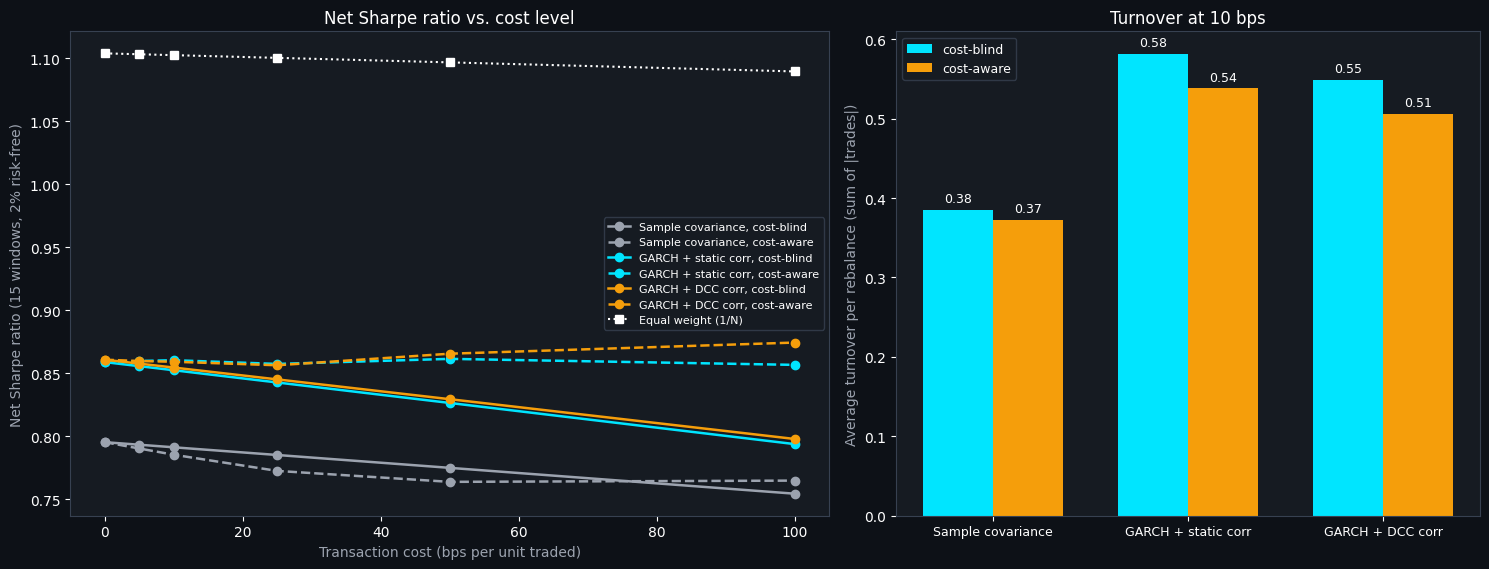

Saved chart_part3_transaction_costs.png


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.8), gridspec_kw={'width_ratios': [1.3, 1]})
fig.patch.set_facecolor('#0d1117')
for ax in axes:
    ax.set_facecolor('#161b22')
    ax.tick_params(colors='white')
    for spine in ax.spines.values():
        spine.set_edgecolor('#374151')

ax = axes[0]
colors = {'Sample covariance': '#9ca3af', 'GARCH + static corr': '#00e5ff', 'GARCH + DCC corr': '#f59e0b'}
for key, label in STRATS:
    for aware, ls in ((False, '-'), (True, '--')):
        s = sens[(sens.covariance == label) & (sens.optimizer == ('cost-aware' if aware else 'cost-blind'))]
        ax.plot(s['cost_bps'], s['net_sharpe'], ls, marker='o', color=colors[label], linewidth=1.8,
                label=f'{label}, {"cost-aware" if aware else "cost-blind"}')
ew = sens[sens.covariance == 'Equal weight (1/N)']
ax.plot(ew['cost_bps'], ew['net_sharpe'], ':', marker='s', color='white', linewidth=1.5, label='Equal weight (1/N)')
ax.set_xlabel('Transaction cost (bps per unit traded)', color='#9ca3af')
ax.set_ylabel('Net Sharpe ratio (15 windows, 2% risk-free)', color='#9ca3af')
ax.set_title('Net Sharpe ratio vs. cost level', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=8)

ax = axes[1]
h = sens[sens.cost_bps == 10]
labels = [l for _, l in STRATS]
x = np.arange(len(labels))
width = 0.36
for off, opt, color in ((-width/2, 'cost-blind', '#00e5ff'), (width/2, 'cost-aware', '#f59e0b')):
    vals = [h[(h.covariance == l) & (h.optimizer == opt)]['avg_turnover'].iloc[0] for l in labels]
    bars = ax.bar(x + off, vals, width, color=color, label=opt)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.01, f'{v:.2f}', ha='center', fontsize=9, color='white')
ax.set_xticks(x)
ax.set_xticklabels(labels, color='white', fontsize=9)
ax.set_ylabel('Average turnover per rebalance (sum of |trades|)', color='#9ca3af')
ax.set_title('Turnover at 10 bps', color='white', fontsize=12)
ax.legend(facecolor='#161b22', edgecolor='#374151', labelcolor='white', fontsize=9)
plt.tight_layout()
plt.savefig('chart_part3_transaction_costs.png', dpi=150, bbox_inches='tight', facecolor='#0d1117')
plt.show()
print('Saved chart_part3_transaction_costs.png')

## 9. Summary and saved tables

In [10]:
sens.drop(columns='strategy').to_csv('part3_cost_sensitivity.csv', index=False)
head.to_csv('part3_cost_comparison_10bps.csv', index=False)
paired_df.to_csv('part3_paired_comparisons.csv', index=False)
turn.to_csv('part3_turnover_by_window.csv')

print('=' * 70)
print('PART 3 SUMMARY: TRANSACTION COSTS AND TURNOVER')
print('=' * 70)
print(f'{len(window_inputs)} windows, {len(window_inputs) - 1} rebalances, cost {COST*1e4:.0f} bps per unit traded (headline)')
print()
print('Net of cost at 10 bps (net return %, vol %, net Sharpe, avg turnover):')
for _, r in head.iterrows():
    print(f'  {r["covariance"]:<22} {r["optimizer"]:<10} {r["net_return_%"]:6.2f}%  {r["vol_%"]:6.2f}%  '
          f'{r["net_sharpe"]:6.3f}  turnover {r["avg_turnover"]:.2f}  (cost drag {r["cost_drag_%_per_yr"]:.2f}%/yr)')
print()
print('Files saved: chart_part3_transaction_costs.png, part3_cost_comparison_10bps.csv, part3_cost_sensitivity.csv, '
      'part3_paired_comparisons.csv, part3_turnover_by_window.csv')

PART 3 SUMMARY: TRANSACTION COSTS AND TURNOVER
15 windows, 14 rebalances, cost 10 bps per unit traded (headline)

Net of cost at 10 bps (net return %, vol %, net Sharpe, avg turnover):
  Sample covariance      cost-blind  18.66%   21.06%   0.791  turnover 0.38  (cost drag 0.09%/yr)
  Sample covariance      cost-aware  18.54%   21.06%   0.785  turnover 0.37  (cost drag 0.08%/yr)
  GARCH + static corr    cost-blind  19.12%   20.08%   0.852  turnover 0.58  (cost drag 0.13%/yr)
  GARCH + static corr    cost-aware  19.32%   20.13%   0.860  turnover 0.54  (cost drag 0.12%/yr)
  GARCH + DCC corr       cost-blind  18.63%   19.46%   0.854  turnover 0.55  (cost drag 0.12%/yr)
  GARCH + DCC corr       cost-aware  18.72%   19.47%   0.859  turnover 0.51  (cost drag 0.11%/yr)
  Equal weight (1/N)     n/a         21.67%   17.85%   1.102  turnover 0.11  (cost drag 0.03%/yr)

Files saved: chart_part3_transaction_costs.png, part3_cost_comparison_10bps.csv, part3_cost_sensitivity.csv, part3_paired_compar